In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\HP\Downloads\Employee_Data_Analysis_Dataset.csv")

In [4]:
df.head()

,EmployeeID,EmployeeName,Age,Gender,Department,JobRole,EducationLevel,Location,HireDate,ExperienceYears,SalaryINR,PerformanceRating,Overtime,Attrition
0,EMP0001,Aarav Joshi,30,Non-binary,Operations,Operations Executive,Master's,Hyderabad,2016-11-16,8.1,674301,2.0,Yes,Yes
1,EMP0002,Aditya Singh,34,Prefer not to say,Operations,Operations Manager,Bachelor's,Bengaluru,2023-08-12,3.4,584678,3.0,Yes,No
2,EMP0003,Pooja Kumar,38,Prefer not to say,Marketing,Marketing Analyst,Master's,Pune,2017-10-17,9.2,766485,3.0,No,No
3,EMP0004,Sneha Shah,24,Non-binary,IT,Data Analyst,Master's,Hyderabad,2025-02-10,0.0,558354,3.0,No,No
4,EMP0005,Arjun Shah,38,Non-binary,IT,QA Engineer,Diploma,Kochi,2016-08-31,9.9,783195,4.0,Yes,No


In [5]:
df.shape

(500, 14)

In [6]:
df.columns

Index(['EmployeeID', 'EmployeeName', 'Age', 'Gender', 'Department', 'JobRole',
       'EducationLevel', 'Location', 'HireDate', 'ExperienceYears',
       'SalaryINR', 'PerformanceRating', 'Overtime', 'Attrition'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EmployeeID         500 non-null    object 
 1   EmployeeName       500 non-null    object 
 2   Age                500 non-null    int64  
 3   Gender             500 non-null    object 
 4   Department         500 non-null    object 
 5   JobRole            500 non-null    object 
 6   EducationLevel     498 non-null    object 
 7   Location           499 non-null    object 
 8   HireDate           500 non-null    object 
 9   ExperienceYears    500 non-null    float64
 10  SalaryINR          500 non-null    int64  
 11  PerformanceRating  499 non-null    float64
 12  Overtime           500 non-null    object 
 13  Attrition          500 non-null    object 
dtypes: float64(2), int64(2), object(10)
memory usage: 54.8+ KB


In [8]:
df.describe()

,Age,ExperienceYears,SalaryINR,PerformanceRating
count,500.000000,500.000000,5.000000e+02,499.000000
mean,32.578000,5.980200,6.082872e+05,3.392786
std,5.050835,3.276684,1.377721e+05,0.886097
min,21.000000,0.000000,2.950970e+05,1.000000
25%,29.000000,3.400000,5.080855e+05,3.000000
50%,33.000000,6.000000,5.995225e+05,3.000000
75%,36.000000,8.400000,6.966792e+05,4.000000
max,47.000000,14.800000,1.072991e+06,5.000000


In [9]:
df.isnull().sum()

EmployeeID           0
EmployeeName         0
Age                  0
Gender               0
Department           0
JobRole              0
EducationLevel       2
Location             1
HireDate             0
ExperienceYears      0
SalaryINR            0
PerformanceRating    1
Overtime             0
Attrition            0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['Department'].unique()

array(['Operations', 'Marketing', 'IT', 'Finance', 'Sales', 'HR', ' it '],
      dtype=object)

In [12]:
df['Department'].value_counts()

Department
IT            90
Marketing     88
Operations    86
Finance       81
Sales         81
HR            73
 it            1
Name: count, dtype: int64

In [13]:
# Remove extra spaces
df['EmployeeName'] = df['EmployeeName'].str.strip()
df['Department'] = df['Department'].str.strip().str.title()
df['Location'] = df['Location'].str.strip()

In [14]:
# Handle missing values
df['EducationLevel'] = df['EducationLevel'].fillna(df['EducationLevel'].mode()[0])

df['Location'] = df['Location'].fillna(df['Location'].mode()[0])

df['PerformanceRating'] = df['PerformanceRating'].fillna(df['PerformanceRating'].median())

In [15]:
df.isnull().sum()

EmployeeID           0
EmployeeName         0
Age                  0
Gender               0
Department           0
JobRole              0
EducationLevel       0
Location             0
HireDate             0
ExperienceYears      0
SalaryINR            0
PerformanceRating    0
Overtime             0
Attrition            0
dtype: int64

In [16]:
# convert Hire date into date format
df['HireDate'] = pd.to_datetime(df['HireDate'])

In [17]:
#check duplicate employee ID'S
df['EmployeeID'].duplicated().sum()

np.int64(0)

In [18]:
# save cleaned dataset
df.to_csv("Employee_Data_Ceaned.csv",index = False)

In [19]:
original_df = pd.read_csv(r"C:\Users\HP\Downloads\Employee_Data_Analysis_Dataset.csv")

In [20]:
original_df[original_df.isnull().any(axis=1)]

,EmployeeID,EmployeeName,Age,Gender,Department,JobRole,EducationLevel,Location,HireDate,ExperienceYears,SalaryINR,PerformanceRating,Overtime,Attrition
17,EMP0018,Kabir Reddy,35,Non-binary,Marketing,Content Specialist,NaN,Mumbai,2017-07-01,6.3,445155,3.0,No,No
62,EMP0063,Aditya Reddy,25,Male,Finance,Finance Manager,Master's,NaN,2020-09-05,6.7,804722,5.0,No,No
108,EMP0109,Neha Iyer,34,Female,Sales,Sales Manager,NaN,Delhi,2017-07-07,12.6,908816,2.0,Yes,No
205,EMP0206,Meera Nair,36,Female,Operations,Process Analyst,Master's,Delhi,2017-05-31,10.2,549230,NaN,No,No


In [21]:
#Total Employees
df['EmployeeID'].nunique()

500

In [22]:
# Department-wise empployee count
df['Department'].value_counts()

Department
It            91
Marketing     88
Operations    86
Finance       81
Sales         81
Hr            73
Name: count, dtype: int64

In [23]:
# Avg salary by department
df.groupby('Department')['SalaryINR'].mean().round(2)

Department
Finance       659847.67
Hr            543544.25
It            707065.24
Marketing     583505.76
Operations    556418.26
Sales         586096.21
Name: SalaryINR, dtype: float64

In [24]:
#Highest and lowest salary
df['SalaryINR'].agg(['max','min'])

max    1072991
min     295097
Name: SalaryINR, dtype: int64

In [25]:
# avg employee experience
df['ExperienceYears'].mean().round(2)

np.float64(5.98)

In [26]:
#avg performance rating by dept
df.groupby('Department')['PerformanceRating'].mean().round(2)

Department
Finance       3.47
Hr            3.34
It            3.31
Marketing     3.51
Operations    3.40
Sales         3.32
Name: PerformanceRating, dtype: float64

In [27]:
# emp attrition analysis
df['Attrition'].value_counts()

Attrition
No     434
Yes     66
Name: count, dtype: int64

In [28]:
# overtime analysis
df['Overtime'].value_counts()

Overtime
No     348
Yes    152
Name: count, dtype: int64

In [29]:
# location wise employee count
df['Location'].value_counts()

Location
Bengaluru    81
Kochi        78
Pune         75
Hyderabad    74
Delhi        73
Chennai      64
Mumbai       55
Name: count, dtype: int64

In [30]:
#department wise salary and experience
df.groupby('Department').agg({
    'SalaryINR':'mean',
    'ExperienceYears':'mean',
    'EmployeeID':'count'
}).round(2)

,SalaryINR,ExperienceYears,EmployeeID
Department,,,
Finance,659847.67,5.86,81
Hr,543544.25,5.80,73
It,707065.24,6.21,91
Marketing,583505.76,6.32,88
Operations,556418.26,5.43,86
Sales,586096.21,6.22,81


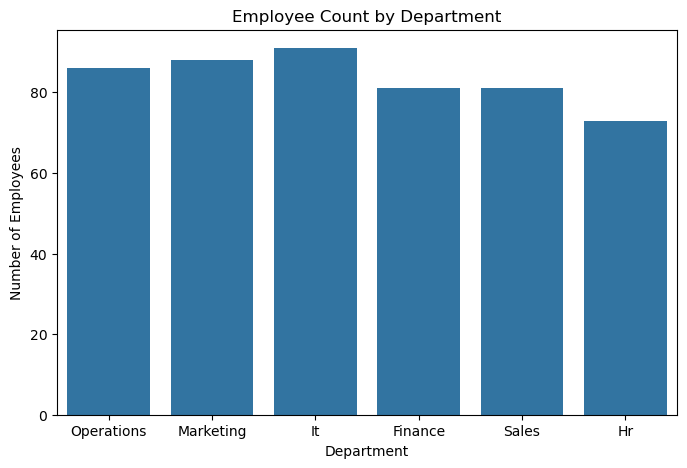

In [31]:
# Department-wise employee count
# Which department has the highest number of employees?
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Department')
plt.title('Employee Count by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.show()

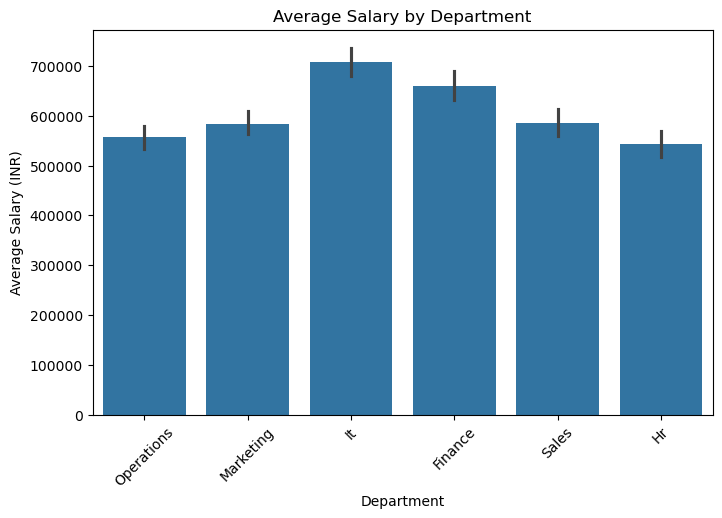

In [32]:
# avg salary by dept
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Department',y='SalaryINR')
plt.title('Average Salary by Department')
plt.xlabel('Department')
plt.ylabel('Average Salary (INR)')
plt.xticks(rotation=45)
plt.show()

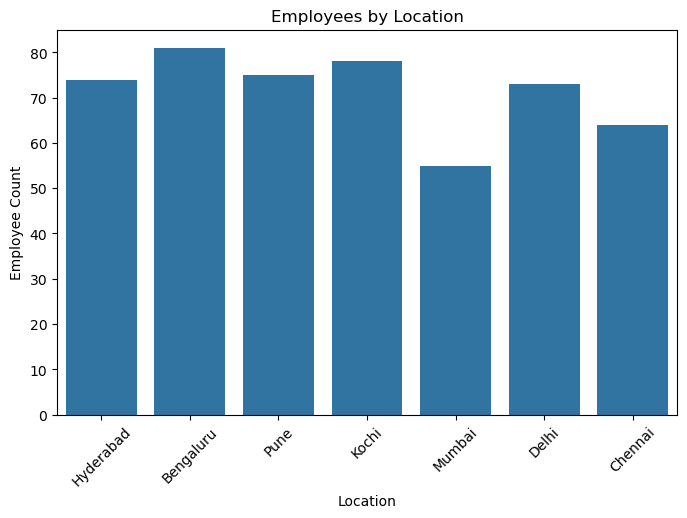

In [33]:
#Employee distribution by location
plt.figure(figsize=(8,5))
sns.countplot(data= df, x='Location')
plt.title('Employees by Location')
plt.xlabel('Location')
plt.ylabel('Employee Count')
plt.xticks(rotation=45)
plt.show()

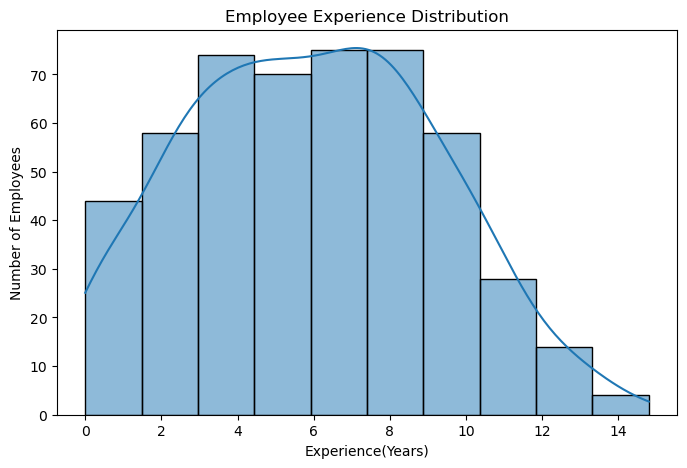

In [34]:
# Employee experience distribution
plt.figure(figsize=(8,5))
sns.histplot(data=df,x='ExperienceYears',bins=10,kde=True)
plt.title('Employee Experience Distribution')
plt.xlabel('Experience(Years)')
plt.ylabel('Number of Employees')
plt.show()

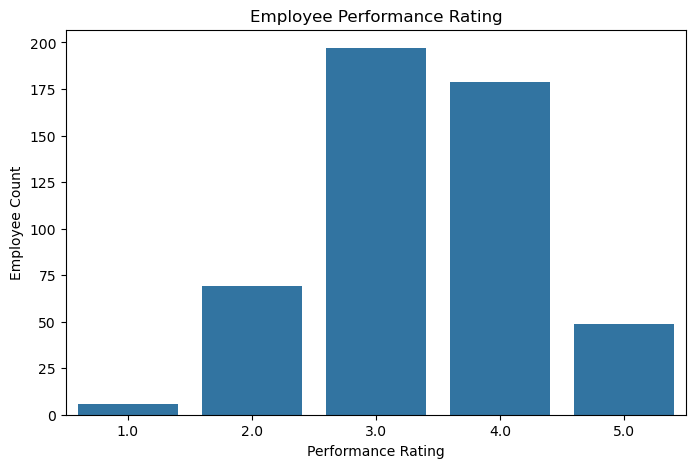

In [35]:
#Performance rating distribution
plt.figure(figsize=(8,5))
sns.countplot(data = df,x='PerformanceRating')
plt.title('Employee Performance Rating')
plt.xlabel('Performance Rating')
plt.ylabel('Employee Count')
plt.show()

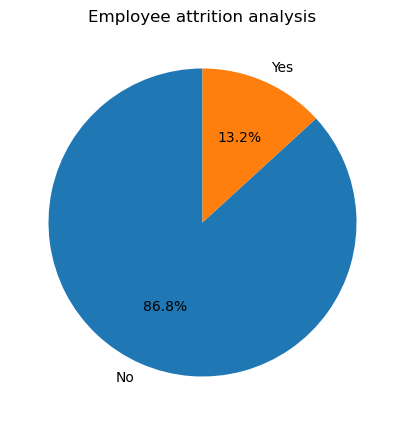

In [36]:
# Employee attrition analysis
plt.figure(figsize=(8,5))
df['Attrition'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Employee attrition analysis')
plt.ylabel('')
plt.show()

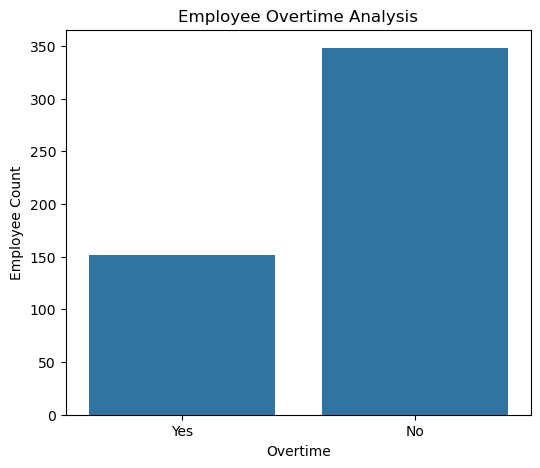

In [37]:
# Overtime Analysis
plt.figure(figsize=(6,5))
sns.countplot(data=df,x='Overtime')
plt.title('Employee Overtime Analysis')
plt.xlabel('Overtime')
plt.ylabel('Employee Count')
plt.show()

In [38]:
df.to_csv(r"C:\Users\HP\Downloads\Employee_Data_Cleaned.csv", index=False)

In [39]:
df['PerformanceRating'].isnull().sum()

np.int64(0)

In [40]:
df.to_csv(r"C:\Users\HP\Downloads\Employee_Data_Cleaned.csv", index=False)